# EDA of Target: EUR→INR
**EUR to INR Transfer Outlook** · shared target part

first look → one feature at a time → grouping → target vs its own past → missing values.

**Shared rules:**
(1) ECB days with a rate, from 1 Feb 2020 · (2) conclusions only from the **training period 2020–2023** · (3) analyse **changes, not levels**.

In [10]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", 30)

DATA_PATH = "/data_daily_base.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
# rate source ends here
df = df[df["date"] <= "2026-10-29"].copy()

t = df[["date", "eur_inr", "is_ecb_day", "weekday"]].copy()
t.head(10)

,date,eur_inr,is_ecb_day,weekday
0,2020-01-01,NaN,0,2
1,2020-01-02,79.9065,1,3
2,2020-01-03,80.0085,1,4
3,2020-01-04,NaN,0,5
4,2020-01-05,NaN,0,6
5,2020-01-06,80.5175,1,0
6,2020-01-07,80.2650,1,1
7,2020-01-08,79.7090,1,2
8,2020-01-09,79.1620,1,3
9,2020-01-10,78.6915,1,4


## 1 · First look

In [11]:
t = t[t["date"] <= "2026-10-29"].copy()
print("From", t["date"].min().date(), "to", t["date"].max().date())

#is rate missing?
display(pd.crosstab(t["is_ecb_day"], t["eur_inr"].isna(),
                    rownames=["is_ecb_day"], colnames=["eur_inr missing"]))

# is an ECB working day, no rate
t[(t["is_ecb_day"] == 1) & (t["eur_inr"].isna())]

From 2020-01-01 to 2026-10-29


eur_inr missing,False,True
is_ecb_day,,
0,0,744
1,1750,0


,date,eur_inr,is_ecb_day,weekday


In [12]:
START, TRAIN_END = "2020-02-01", "2023-12-31"

d = t[t["eur_inr"].notna() & (t["date"] >= START)].copy()
d = d.sort_values("date").reset_index(drop=True)

# Build previous rate, gap and daily change
d["eur_inr_prev"] = d["eur_inr"].shift(1)
d["days_since_prev"] = d["date"].diff().dt.days
# daily change in %
d["ret_1d"] = 100 * np.log(d["eur_inr"] / d["eur_inr_prev"])
d["period"] = np.where(d["date"] <= TRAIN_END, "train", "test")

tr = d[d["period"] == "train"].copy()

print("Rows after filter:", len(d), "| train:", len(tr), "| test:", len(d) - len(tr))
print("Last date with a rate:", d["date"].max().date(), "| last date in file:", t["date"].max().date())
display(d["eur_inr"].describe().round(2))
d["days_since_prev"].value_counts().sort_index()

Rows after filter: 1728 | train: 1005 | test: 723
Last date with a rate: 2026-10-29 | last date in file: 2026-10-29


,eur_inr
count,1728.00
mean,91.42
std,8.49
min,77.23
25%,86.39
50%,89.15
75%,93.10
max,112.32


,count
days_since_prev,
1.0,1371
2.0,4
3.0,336
4.0,7
5.0,9


### Findings from first look
- The data covers **2,494 calendar days** (1 Jan 2020 – 29 Oct 2026), with no duplicate or missing dates.
- `eur_inr` is empty on **~30 %** of days. All of these are weekends and ECB holidays (`is_ecb_day = 0`).
- After applying rule 1: **1,728 ECB days** (train 1,261 · test 467).
- Level: mean 91.4, median 89.2, range 77.2–112.3 INR per EUR (plausible). The large std (8.5) comes from the **long-term trend** (≈ 79 in 2020 → ≈ 106 in 2026), not from daily jumps → we analyse changes.
- Gaps between fixes: 1 day (Tue–Fri) is normal, 3 days on Mondays (weekend), 4–5 days around Easter and Christmas.
- `eur_inr_prev` is the previous fix's rate (built with `shift(1)` **after** filtering to ECB days; otherwise Monday would get Sunday's empty value). It is known on the prediction day, so there is **no leakage**.

## 2 · One feature at a time

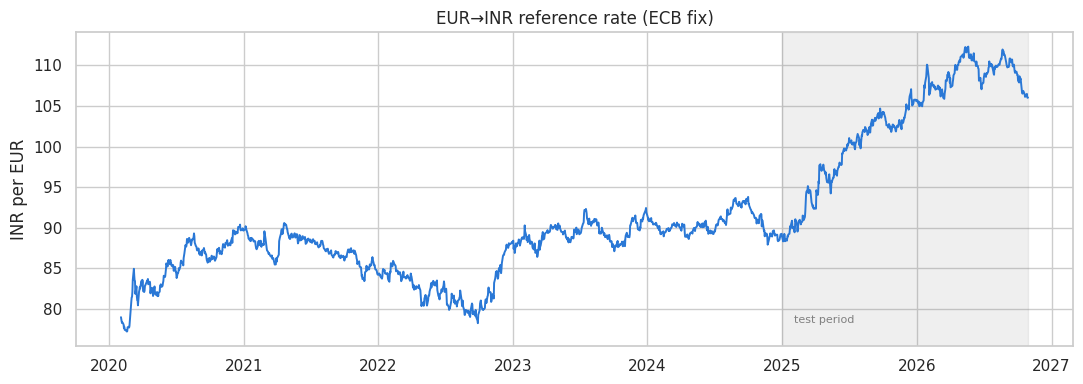

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(d["date"], d["eur_inr"], color=PALETTE[0], lw=1.4)
ax.axvspan(pd.Timestamp("2025-01-01"), d["date"].max(), color="grey", alpha=0.12)
ax.text(pd.Timestamp("2025-02-01"), d["eur_inr"].min() + 1, "test period", fontsize=8, color="grey")
ax.set_title("EUR→INR reference rate (ECB fix)"); ax.set_ylabel("INR per EUR")
plt.tight_layout(); plt.show()

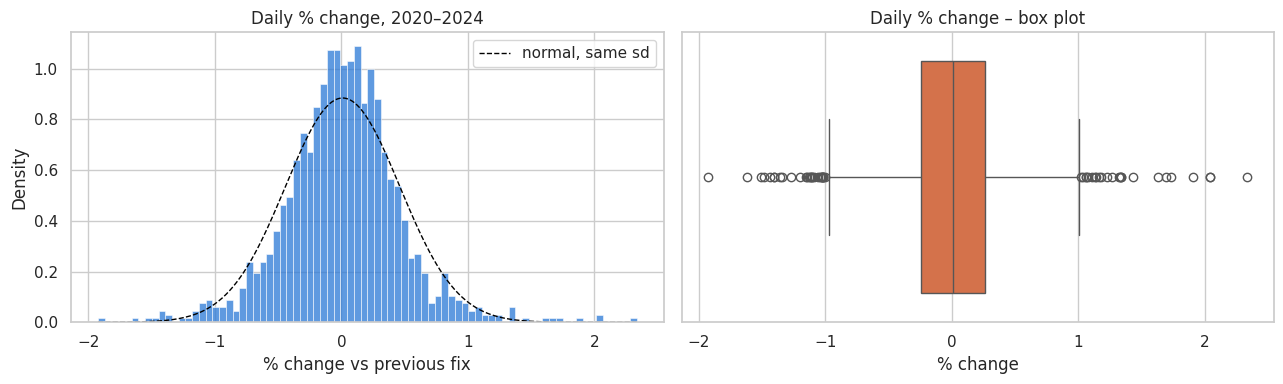

mean 0.009%  sd 0.451%  skew 0.20  excess kurtosis 2.34
median |change| 0.26%, 90th pct 0.71%, 99th pct 1.42%
Outlier days: 52 of 1260 (4.1%)


,date,eur_inr,ret_1d
715,2022-11-11,83.2253,2.333403
35,2020-03-23,82.1255,2.042626
20,2020-03-02,80.9170,2.037498
29,2020-03-13,81.8765,-1.925131
300,2021-04-07,88.3675,1.905037
24,2020-03-06,83.5860,1.729268
1156,2024-08-05,92.2765,1.692349
25,2020-03-09,84.9600,1.630452


In [18]:
r = tr["ret_1d"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(r, bins=80, stat="density", ax=axes[0])
x = np.linspace(r.min(), r.max(), 300)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="black", ls="--", lw=1, label="normal, same sd")
axes[0].set_title("Daily % change, 2020–2024"); axes[0].set_xlabel("% change vs previous fix"); axes[0].legend()
sns.boxplot(x=r, ax=axes[1], color=PALETTE[1])
axes[1].set_title("Daily % change – box plot"); axes[1].set_xlabel("% change")
plt.tight_layout(); plt.show()

print(f"mean {r.mean():.3f}%  sd {r.std():.3f}%  skew {r.skew():.2f}  excess kurtosis {r.kurt():.2f}")
print("median |change| {:.2f}%, 90th pct {:.2f}%, 99th pct {:.2f}%".format(*r.abs().quantile([.5, .9, .99])))

# IQR outliers
q1, q3 = r.quantile([0.25, 0.75]); iqr = q3 - q1
out = tr[(tr["ret_1d"] < q1 - 1.5 * iqr) | (tr["ret_1d"] > q3 + 1.5 * iqr)]
print(f"Outlier days: {len(out)} of {len(r)} ({100*len(out)/len(r):.1f}%)")
out.loc[out["ret_1d"].abs().sort_values(ascending=False).index, ["date", "eur_inr", "ret_1d"]].head(8)

weekly change: sd 1.01%, median |change| 0.58%
typical day moves 1,000 EUR by ≈ 222 INR, a typical week by ≈ 509 INR


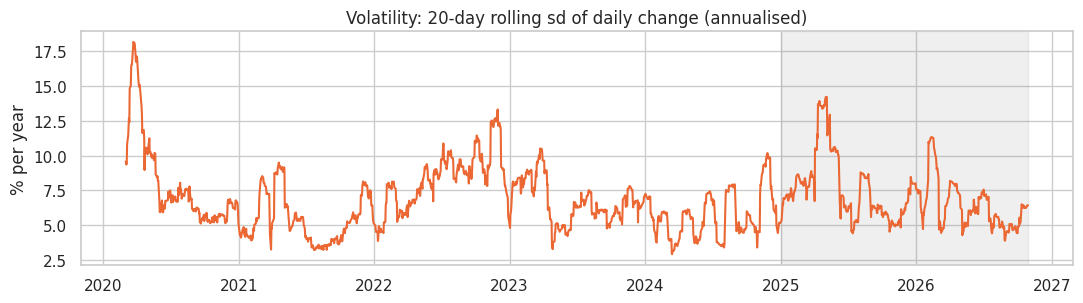

In [19]:
# Weekly change and money terms
wk = tr.set_index("date")["eur_inr"].resample("W-FRI").last()
wr = (100 * np.log(wk / wk.shift(1))).dropna()
avg = tr["eur_inr"].mean()
print(f"weekly change: sd {wr.std():.2f}%, median |change| {wr.abs().median():.2f}%")
print(f"typical day moves 1,000 EUR by ≈ {r.abs().median()/100*avg*1000:.0f} INR, a typical week by ≈ {wr.abs().median()/100*avg*1000:.0f} INR")

# Rolling volatility
vol = d.set_index("date")["ret_1d"].rolling(20).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(vol.index, vol, color=PALETTE[1])
ax.axvspan(pd.Timestamp("2025-01-01"), d["date"].max(), color="grey", alpha=0.12)
ax.set_title("Volatility: 20-day rolling sd of daily change (annualised)"); ax.set_ylabel("% per year")
plt.tight_layout(); plt.show()

### Findings from distributions
- **Regimes:** the rate rose sharply in 2020, fell through 2021, then rose slowly to 2024; the strongest rise is in 2025 (test period).
- The daily change is centred at ~0 (mean 0.009 %) and nearly symmetric (skew 0.20).
- **Fat tails:** excess kurtosis 2.34 → more calm days and more big jumps than a normal distribution. 52 days (4.1 %) are IQR outliers.
- **Typical size:** half of all days move < 0.26 % (≈ 220 INR per 1,000 EUR); 99th percentile 1.42 %. A typical week moves ≈ 0.58 % (≈ 510 INR per 1,000 EUR).
- The biggest moves cluster in **March 2020 (COVID)** and around **11 Nov 2022 (US inflation surprise)**. They are real market events, not errors.
- **Volatility clusters:** calm and turbulent periods last weeks to months (spikes in 2020, late 2022, 2025).

## 3 · Grouping: weekday and day of month

,count,mean,median,std
wd,,,,
Mon,247,0.091,0.090,0.492
Tue,256,-0.004,0.007,0.405
Wed,254,-0.025,-0.021,0.428
Thu,255,0.037,0.042,0.422
Fri,248,-0.050,-0.058,0.494


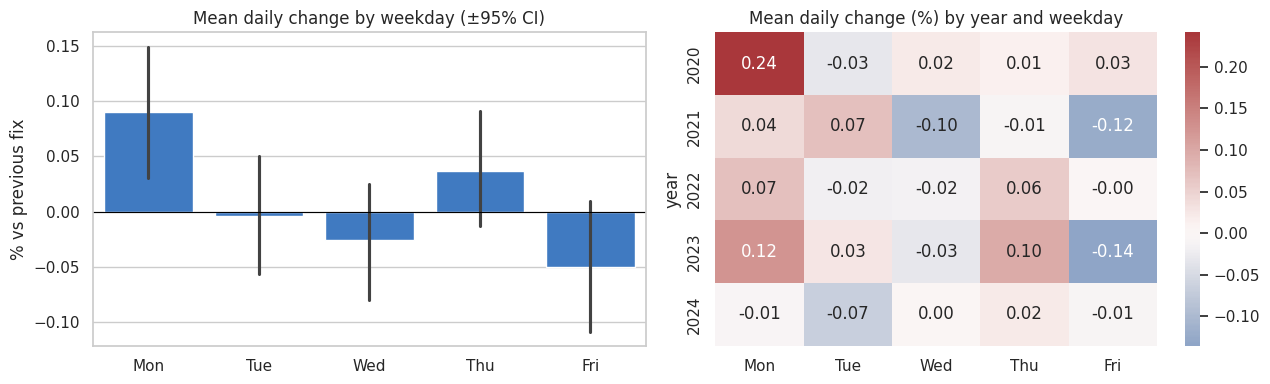

KruskalResult(statistic=np.float64(12.643413527011035), pvalue=np.float64(0.01315618487411757))


In [20]:
wd_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri"}
tr["wd"] = tr["weekday"].map(wd_names)
order = list(wd_names.values())

display(tr.groupby("wd")["ret_1d"].agg(["count", "mean", "median", "std"]).reindex(order).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=tr, x="wd", y="ret_1d", order=order, color=PALETTE[0], errorbar=("ci", 95), ax=axes[0])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("Mean daily change by weekday (±95% CI)"); axes[0].set_xlabel(""); axes[0].set_ylabel("% vs previous fix")

grid = tr.groupby([tr["date"].dt.year, "wd"])["ret_1d"].mean().unstack()[order]
sns.heatmap(grid, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Mean daily change (%) by year and weekday"); axes[1].set_ylabel("year"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(stats.kruskal(*[g.dropna() for _, g in tr.groupby("weekday")["ret_1d"]]))

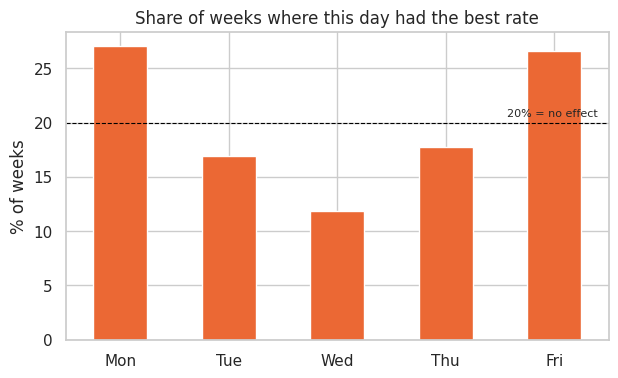

In [21]:
# Which weekday had the best rate of the week?
tr["week"] = tr["date"].dt.to_period("W-FRI")
full = tr.groupby("week")["weekday"].transform("count") == 5
best_idx = tr[full].groupby("week")["eur_inr"].idxmax()
best_share = tr.loc[best_idx, "wd"].value_counts(normalize=True).reindex(order)

ax = (100 * best_share).plot.bar(color=PALETTE[1], figsize=(7, 4), rot=0)
ax.axhline(20, color="black", ls="--", lw=0.8); ax.text(4.4, 20.6, "20% = no effect", ha="right", fontsize=8)
ax.set_title("Share of weeks where this day had the best rate"); ax.set_ylabel("% of weeks"); ax.set_xlabel("")
plt.show()

,best_vs_avg_%,range_%
count,59.00,59.00
mean,1.32,2.70
std,0.64,1.18
min,0.45,1.11
25%,0.83,1.87
50%,1.20,2.50
75%,1.70,3.43
max,3.20,5.74


Median money at stake (best vs average day): 1044 INR per 1,000 EUR


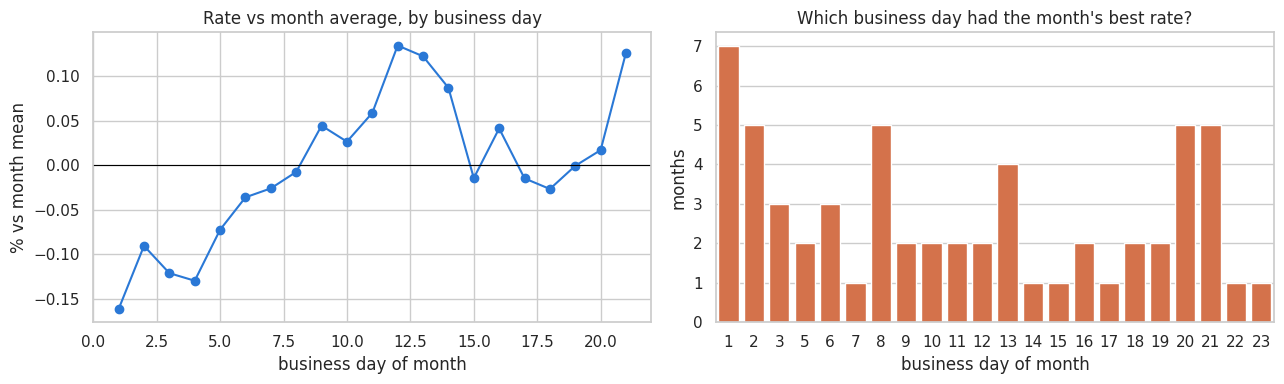

In [22]:
# Day of month and the "best day to send" gap
tr["month_p"] = tr["date"].dt.to_period("M")
tr["bday"] = tr.groupby("month_p").cumcount() + 1
tr["rel_month"] = 100 * (tr["eur_inr"] / tr.groupby("month_p")["eur_inr"].transform("mean") - 1)

m = tr.groupby("month_p")["eur_inr"].agg(["max", "min", "mean"])
m["best_vs_avg_%"] = 100 * (m["max"] / m["mean"] - 1)
m["range_%"] = 100 * (m["max"] / m["min"] - 1)
display(m[["best_vs_avg_%", "range_%"]].describe().round(2))
print(f"Median money at stake (best vs average day): {1000*(m['max']-m['mean']).median():.0f} INR per 1,000 EUR")

best_pos = tr.loc[tr.groupby("month_p")["eur_inr"].idxmax(), "bday"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
prof = tr[tr["bday"] <= 21].groupby("bday")["rel_month"].mean()
axes[0].plot(prof.index, prof.values, marker="o", color=PALETTE[0]); axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("Rate vs month average, by business day"); axes[0].set_xlabel("business day of month"); axes[0].set_ylabel("% vs month mean")
sns.countplot(x=best_pos, color=PALETTE[1], ax=axes[1])
axes[1].set_title("Which business day had the month's best rate?"); axes[1].set_xlabel("business day of month"); axes[1].set_ylabel("months")
plt.tight_layout(); plt.show()

### Findings from grouping
- **Monday effect:** Monday's change averages ≈ **+0.09 %** and is positive in 4 of 5 years; Friday tends to be negative. Kruskal–Wallis **p ≈ 0.013** → the weekday difference is probably real.
- Part of the reason: Monday's change covers **3 calendar days** (weekend), so news piles up.
- The effect is **small in money**: ≈ 50–80 INR per 1,000 EUR, much less than a typical weekly move (≈ 510 INR).
- Monday (27 %) and Friday (27 %) are most often the week's best day, Wednesday least (12 %). This "edges win" pattern is what a random walk produces, so it is not proof of a weekday effect on its own.
- **Best day of the month:** it beats the month's average day by a median **≈ 1.2 %** (≈ **1,040 INR per 1,000 EUR**); the monthly high–low range is ≈ 2.5 %. This is the prize our model competes for against the *best-day-to-send* baseline.
- Early business days sit below the month average and later ones above. With the upward trend of 2020–2024 this is most likely **trend, not payday** (to check against `is_payday_window` in the calendar part). The best day falls most often at the start or end of the month (random-walk pattern again).

## 4 · The target against its own past (autocorrelation)

lag-1 corr of change : 0.014
lag-1 corr of |change|: 0.162 | noise band ± 0.055


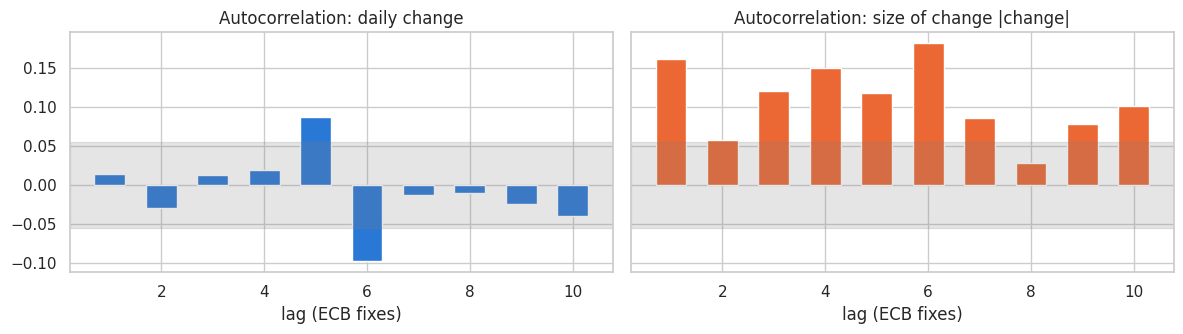

In [23]:
lags = range(1, 11)
acf_ret = [r.autocorr(k) for k in lags]
acf_abs = [r.abs().autocorr(k) for k in lags]
band = 1.96 / np.sqrt(len(r))          # ≈ 95% noise band

print("lag-1 corr of change :", round(acf_ret[0], 3))
print("lag-1 corr of |change|:", round(acf_abs[0], 3), "| noise band ±", round(band, 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, vals, title, col in [(axes[0], acf_ret, "daily change", PALETTE[0]),
                             (axes[1], acf_abs, "size of change |change|", PALETTE[1])]:
    ax.bar(list(lags), vals, color=col, width=0.6)
    ax.axhspan(-band, band, color="grey", alpha=0.2)
    ax.set_title(f"Autocorrelation: {title}"); ax.set_xlabel("lag (ECB fixes)")
plt.tight_layout(); plt.show()

### Findings from autocorrelation
- The **direction** of the daily change is almost unpredictable from its own past: lag-1 correlation 0.01, all bars inside the noise band except a small one at lag 5 (≈ one week, 0.09).
- The **size** of the change is clearly autocorrelated (lag-1 ≈ 0.16): big days follow big days → **volatility clustering**.

## 5 · Missing values (all columns)

In [17]:
print(df["date"].min().date(), "to", df["date"].max().date())
miss = df.isna().sum().to_frame("n_missing")
miss["percent"] = (100 * miss["n_missing"] / len(df)).round(1)
miss[miss["n_missing"] > 0].sort_values("percent", ascending=False)

2020-01-01 to 2026-10-29


,n_missing,percent
eur_inr,744,29.8
eur_usd_usd_per_eur,2,0.1
us_10y_treasury_yield_pct,2,0.1
brent_usd_per_barrel,2,0.1
usd_inr_inr_per_usd,2,0.1
broad_usd_index_2006_100,2,0.1
fpi_total_day,1,0.0
fpi_equity_day,1,0.0
fpi_debt_day,1,0.0


### Findings from missing values
- `eur_inr` ≈ 30 % is weekends and ECB holidays.
- FPI flow columns ≈ 0.8 %: reporting gaps. Market columns (EUR/USD, USD/INR, Brent, US 10Y, dollar index) ≈ 0.1 % US holidays.
- Missingness follows the **calendar**, not chance → we work on ECB days only, and weekend information (FPI flows, events) has to be carried to the next ECB day in feature engineering.

## 6 · Take-aways for feature engineering

| Feature | Decision | Why |
|---|---|---|
| Rate level (`eur_inr`) | Don't use directly | It trends upward, so it looks linked to everything |
| Daily / weekly % change | keep as target | This is what we want to predict |
| Previous rate (`eur_inr_prev`) | Only to calculate changes | Same information as the level |
| Recent volatility (20-day) | Add | Big moves come in groups |
| Recent trend (5- and 20-day change) | Add, test | May show if the rate is rising or falling |
| Weekday | Keep, test | Mondays rise slightly |
| Day of month | Drop | Only reflects the overall trend |

**Key messages**
1. The rate usually moves little (≈ 0.3 % a day, ≈ 0.6 % a week), but big jumps happen.
2. Sending on the best day of the month instead of an average day gives ≈ 1.2 % more (≈ 1,040 INR per 1,000 EUR).
3. Past changes can't predict the direction, only how much the rate may move.
4. Mondays are slightly better; the day of the month doesn't matter.
5. Judge the model by how much of the best-day gain it captures.